# 03 · Can we do it with only the link?

**In one sentence:** we turn every link into 40 numbers computed from the link text alone, and train the same kind of models as in notebook 02 on them.

**Why:** in notebook 02 the models used columns that our app can't get, such as counts from the downloaded web page. A user only types or pastes a **link**. So the honest question for an app is: how well can a model do from the link alone?

**Published comparison:** a 2026 paper (Frontiers in Computer Science) reports XGBoost at 99.74% on link features. It used a different split, so the comparison is only rough.

### What happens below
1. **Feature engineering:** turn each link into 40 numbers (`src/phishguard/features.py`).
2. **Exploration:** compare those numbers for phishing and legitimate links.
3. **Models:** train Random Forest and XGBoost, on the same 5 splits and with the same routine as notebook 02.
4. **Error analysis:** look at the phishing links the model still misses.

## Step 1 · Turn each link into numbers

Models can't read text directly; they need numbers. `extract_features` reads each link and measures 40 things about it, using **only the link text**: nothing downloaded, no outside lists.

The result `X` is a table with one row per link and one column per feature: 234,204 rows × 40 columns.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from phishguard.data import load_clean, TARGET
from phishguard.features import extract_features
from phishguard.experiment import run, summary_table
from phishguard.modeling import param_grid

df = load_clean()
y = df[TARGET]
X = extract_features(df["URL"])
X.shape

(234204, 40)

### The 40 features, in groups

| Group | Features | Why it might help |
|---|---|---|
| Size | `url_length`, `host_length`, `path_length`, `query_length`, `domain_length`, `tld_length` | Phishing links are often long, to hide the real site |
| Character counts | `num_digits`, `num_dots`, `num_hyphens`, `num_slashes`, `num_at`, `num_percent`, … and ratios | Random or disguised links have unusual mixes of characters |
| Host structure | `num_subdomains`, `host_dots`, `host_hyphens`, `has_ip`, `has_port`, `has_www`, `has_punycode` | `paypal.com.secure-login.xyz` hides a brand in the subdomain; `xn--` hides look-alike letters |
| Scheme | `is_https` | Whether the link starts with `https://` |
| Platform | `on_hosting_platform`, `is_shortener` | Free hosting (`web.app`, `weebly`) and link shorteners are popular with attackers |
| Path and query | `path_depth`, `num_query_params`, `has_fragment`, `double_slash_in_path` | What comes after the site name |
| Words | `suspicious_words` (whole words like login, verify, account), `longest_token` | Whole words only, so `freedomhouse` doesn't count as "free" |
| Randomness | `url_entropy`, `host_entropy` | **Entropy** measures how random the letters are: `google` is low, `x7q9kz` is high |

**One design choice:** counts and ratios are measured **without** the leading `https://www.`. Only `is_https` and `has_www` know about that part, so no other feature secretly repeats it (decision D9).

## Step 2 · A look at the first rows
Each row is one link; each column is one feature.

In [2]:
X.head()

,url_length,num_letters,num_digits,letter_ratio,digit_ratio,special_ratio,num_dots,num_hyphens,num_underscores,num_slashes,...,on_hosting_platform,is_shortener,path_depth,num_query_params,has_fragment,double_slash_in_path,suspicious_words,longest_token,url_entropy,host_entropy
0,20,19,0,0.950000,0.0,0.050000,1,0,0,0,...,0,0,0,0,0,0,0,16,3.546439,3.657268
1,12,10,0,0.833333,0.0,0.166667,1,1,0,0,...,0,0,0,0,0,0,0,5,3.251629,3.327820
2,18,16,0,0.888889,0.0,0.111111,2,0,0,0,...,0,0,0,0,0,0,0,12,3.572431,3.629220
3,15,14,0,0.933333,0.0,0.066667,1,0,0,0,...,0,0,0,0,0,0,0,11,3.506891,3.576618
4,22,21,0,0.954545,0.0,0.045455,1,0,0,0,...,0,0,0,0,0,0,0,18,3.413088,3.430457


## Step 3 · How do phishing and legitimate links differ?

This is **exploratory data analysis**: before training, we look at the data ourselves.

**How to read the histograms:**
- Each panel is one feature. The horizontal axis is its value; the height shows how common that value is.
- The two colours are the two classes. Each is scaled separately, so the shapes can be compared even though there are more legitimate links.
- The top 1% of values are cut off so the charts stay readable.

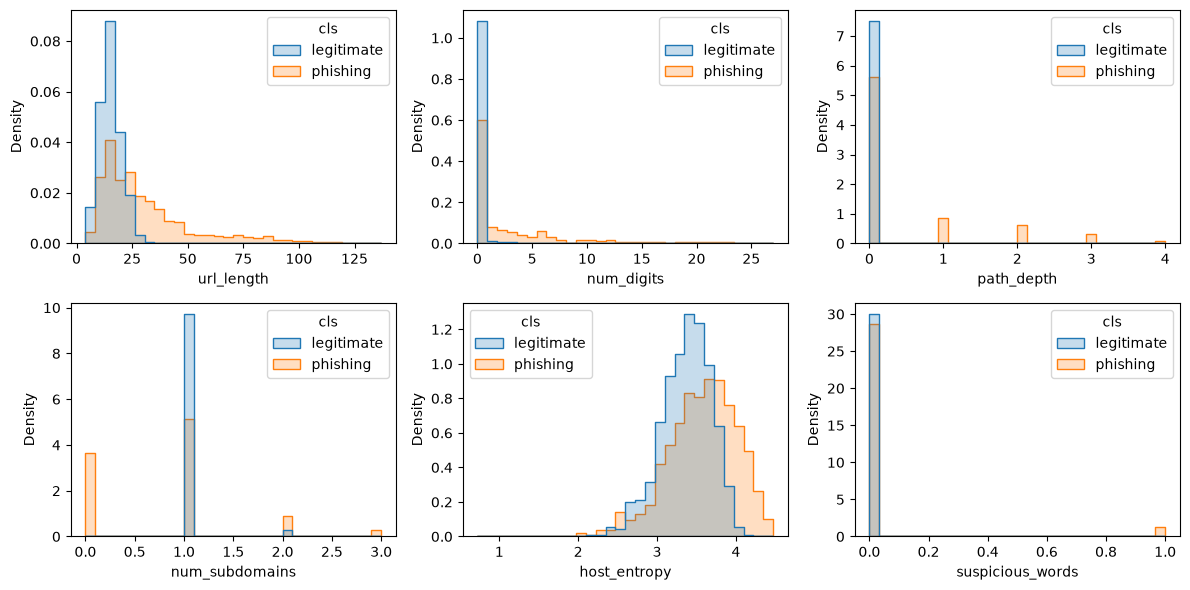

In [3]:
cols = ["url_length", "num_digits", "path_depth", "num_subdomains", "host_entropy", "suspicious_words"]
plot_df = X[cols].assign(cls=y.map({0: "legitimate", 1: "phishing"}))
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, col in zip(axes.flat, cols):
    clip = plot_df[col].quantile(0.99)
    sns.histplot(data=plot_df[plot_df[col] <= clip], x=col, hue="cls", stat="density",
                 common_norm=False, bins=30, element="step", ax=ax)
fig.tight_layout()
plt.show()

Below, the **average** of every feature for each class:

In [4]:
X.groupby(y.map({0: "legitimate", 1: "phishing"})).mean().T.round(3)

is_phishing,legitimate,phishing
url_length,15.229,36.613
num_letters,13.933,28.415
num_digits,0.051,4.329
letter_ratio,0.907,0.810
digit_ratio,0.004,0.083
special_ratio,0.089,0.107
num_dots,1.162,1.971
num_hyphens,0.083,0.704
num_underscores,0.000,0.082
num_slashes,0.000,0.646


**What stands out:**
- Legitimate links are short (15 characters on average vs 37), with almost no digits (0.05 vs 4.3).
- `path_length`, `num_slashes` and `query_length` are **exactly 0** for every legitimate link. Every legitimate link in this dataset is just a homepage, with nothing after the site name.
- Phishing links vary much more.

That last point is odd: real legitimate links often have paths like `/login` or `/products/42`. We come back to it in Milestone 3, because it turns out to matter a lot.

## Step 4 · Model 1: Random Forest

The same method as in notebook 02: 300 decision trees that vote, now looking at our 40 features instead of the dataset's columns.

**Settings we try:** `max_depth` (unlimited, or 30 questions per tree) and `min_samples_leaf` (1 or 3 links per final answer).

`run(...)` does the same as in notebook 02: for each of 5 splits, choose settings and threshold on validation, then score test once.

In [5]:
rf = run(
    "Random Forest (URL features)",
    lambda max_depth, min_samples_leaf: RandomForestClassifier(
        n_estimators=300, max_depth=max_depth, min_samples_leaf=min_samples_leaf, n_jobs=-1, random_state=42),
    param_grid(max_depth=[None, 30], min_samples_leaf=[1, 3]),
    X, y, df, features="URL features", group="m2",
)

## Step 5 · Model 2: XGBoost

Trees built one after another, each fixing the previous ones' mistakes. Compared with notebook 02 we add two settings that make it harder to overfit (to memorise the training links instead of learning general rules):
- `subsample=0.8`, `colsample_bytree=0.8`: each tree sees a random 80% of the links and of the features;
- `min_child_weight` (1 or 5): a tree may not create a rule that applies to only a handful of links.

The table at the end compares both models; the columns mean the same as in notebook 02 (average ± standard deviation over 5 splits).

In [6]:
xgb = run(
    "XGBoost (URL features)",
    lambda max_depth, min_child_weight: XGBClassifier(
        max_depth=max_depth, min_child_weight=min_child_weight, n_estimators=500, learning_rate=0.1,
        subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=42),
    param_grid(max_depth=[6, 10], min_child_weight=[1, 5]),
    X, y, df, features="URL features", group="m2",
)
summary_table([rf, xgb])

,accuracy (%),f1 (%),roc_auc,pr_auc,mcc,tpr_at_fpr_1pct (%),"accuracy, seed 42 [95% CI]"
model,,,,,,,
Random Forest (URL features),99.63 ± 0.04,99.56 ± 0.05,0.9972 ± 0.0002,0.9979 ± 0.0002,0.9925 ± 0.0008,99.34 ± 0.08,"99.70% [99.63%, 99.76%]"
XGBoost (URL features),99.63 ± 0.03,99.57 ± 0.03,0.9973 ± 0.0004,0.9980 ± 0.0003,0.9925 ± 0.0006,99.35 ± 0.08,"99.68% [99.62%, 99.74%]"


**How to read this:**
- Both models get **99.63%** from the link text alone. That's close to the published 99.74%, and only a little below notebook 02's models, which had more information.
- The difference between the two models is smaller than the ±, so neither is better.
- `tpr_at_fpr_1pct` ≈ 99.3%: allowing 1 false alarm per 100 legitimate links, the models catch 99.3% of phishing.

## Step 6 · Which features does XGBoost rely on?
The 15 features that helped XGBoost's trees the most, on the main split (seed 42). Note which ones are at the top: we come back to this in Milestone 3.

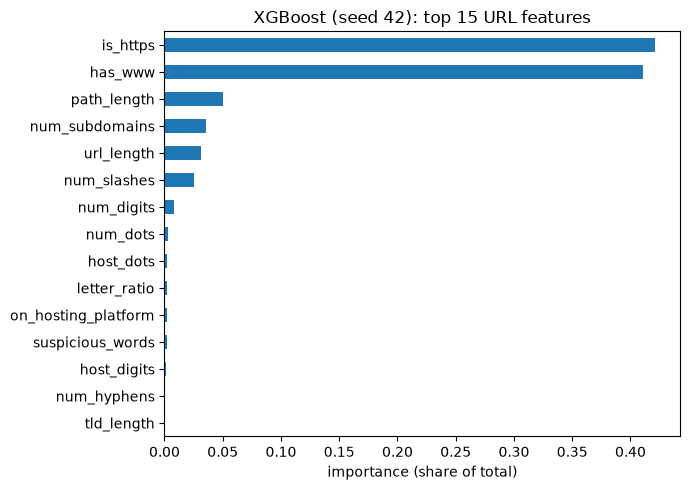

In [7]:
pd.Series(xgb.reference.model.feature_importances_, index=X.columns).sort_values().tail(15).plot.barh(figsize=(7, 5))
plt.title("XGBoost (seed 42): top 15 URL features")
plt.xlabel("importance (share of total)")
plt.tight_layout()
plt.show()

## Step 7 · What does it still get wrong?

This is **error analysis**: we read the links the model gets wrong to understand its weak spots.

We look at mistakes on the **validation** part, never the test part. The test part is kept for the final score only, so we don't learn anything from it along the way.

The code below finds the phishing links the model missed, and checks how many of them look like `https://www.<site>` with nothing after it.

In [8]:
_, val_idx, _ = xgb.reference_splits
val_prob = pd.Series(xgb.reference.val_prob, index=val_idx)
missed = df.loc[val_idx][(y[val_idx] == 1) & (val_prob < xgb.reference.threshold)]
print(f"missed phishing URLs on validation: {len(missed)}")
print("share that are a bare https://www.<domain> homepage:",
      round(missed["URL"].str.match(r"^https://www\.[^/]+$").mean(), 3))
missed["URL"].head(10)

missed phishing URLs on validation: 117
share that are a bare https://www.<domain> homepage: 1.0


1274                 https://www.lglsvy.top
1339                https://www.mutfakci.az
3362             https://www.netflix-vn.com
5796             https://www.glambeaute.com
12194             https://www.tenxstack.com
12564               https://www.niktell.com
18076                https://www.mndnrd.top
20091    https://www.emmezaon-jp.zjynwc.top
25845                 https://www.k365v.com
27979       https://www.chibabamk.fytqm.com
Name: URL, dtype: str

## What we learned

1. **From the link alone, our 40 features reach 99.63%** (Random Forest and XGBoost tie). That's close to the published 99.74%.
2. **Every one of the 117 phishing links it missed** (on validation) is a bare `https://www.<site>` homepage, for example `https://www.netflix-vn.com`. That is exactly what *every* legitimate link in this dataset looks like.
3. For those links, the only clue left is the **site name itself**: a fake brand like `netflix-vn`, a random name like `lglsvy`, a cheap ending like `.top`.

**Next, notebook 04:** a model that reads the link letter by letter, so it can learn from the site name directly. After that, Milestone 3 asks why legitimate links in this dataset all look the same.